In [1]:
import json
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from jaxley_ephys.base import detect_events

In [21]:
def load_specimen(specimen_id: int):
    data_path = Path(f"tests/data/cell_{specimen_id}_data.npz")
    meta_path = Path(f"tests/data/cell_{specimen_id}_meta.json")
    if not data_path.exists() or not meta_path.exists():
        raise FileNotFoundError(
            f"Missing cached specimen {specimen_id}. Run tests/load_testdata.py first."
        )

    with np.load(data_path, allow_pickle=True) as npz:
        arr = {name: npz[name] for name in npz.files}
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    return meta, arr


specimen_id = int(sorted(Path("tests/data").glob("cell_*_meta.json"))[2].stem.split("_")[1])
meta, arr = load_specimen(specimen_id)

long_square_idx = np.where(arr["stimulus_names"] == "Long Square")[0]
selected = long_square_idx

t_batch = jnp.asarray(np.stack(arr["t"][selected]))
v_batch = jnp.asarray(np.stack(arr["v"][selected]))
i_batch = jnp.asarray(np.stack(arr["i"][selected]))

t_cutoff = 3.0 
t_short = jnp.all(t_batch <= t_cutoff, axis=0)
t_batch = t_batch[:, t_short]
v_batch = v_batch[:, t_short]
i_batch = i_batch[:, t_short]

t0_batch = jnp.asarray(arr["stimulus_start_times"][selected])
t1_batch = t0_batch + jnp.asarray(arr["stimulus_durations"][selected])

detect_events_vmapped = jax.vmap(
    lambda t, v, i, t0, t1: detect_events(t, v, i, t0, t1, max_spikes=64),
    in_axes=(0, 0, 0, 0, 0),
)
events_batch = detect_events_vmapped(t_batch, v_batch, i_batch, t0_batch, t1_batch)

print(f"Loaded specimen {specimen_id} with {len(selected)} long-square sweeps")

Loaded specimen 519832676 with 14 long-square sweeps


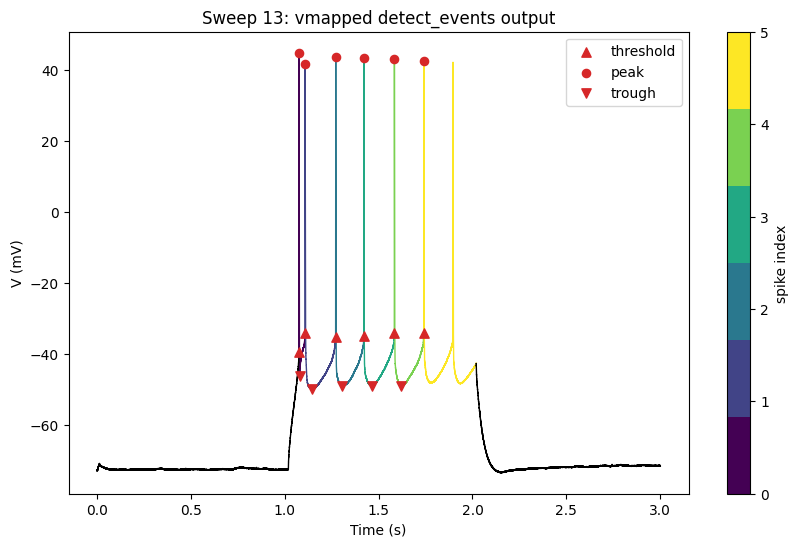

In [44]:
sweep_k = 13
t = t_batch[sweep_k]
v = v_batch[sweep_k]
ev = jax.tree.map(lambda x: np.asarray(x[sweep_k]), events_batch)

fig, ax = plt.subplots(figsize=(10, 6))

spike_ids = np.asarray(ev.spikes)
n_spikes = int(spike_ids.max())
cmap = plt.get_cmap("viridis", n_spikes + 1)

t_np = np.asarray(t)
v_np = np.asarray(v)

for spike_id in range(n_spikes + 1):
    mask = spike_ids == spike_id
    ax.plot(t_np, np.where(mask, v_np, np.nan), color=cmap(spike_id), lw=1)

# background (spike_id == -1) in black
ax.plot(t_np, np.where(spike_ids == -1, v_np, np.nan), color="black", lw=1)

sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_clim(0, n_spikes)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, ticks=np.arange(n_spikes + 1))
cbar.set_label("spike index")

thr_idx = ev.threshold_idxs[ev.threshold_valid]
pk_idx = ev.peak_idxs[ev.peak_valid]
tr_idx = ev.trough_idxs[ev.trough_valid]

ax.scatter(t[thr_idx], v[thr_idx], marker="^", s=45, color="tab:red", label="threshold", zorder=20)
ax.scatter(t[pk_idx], v[pk_idx], marker="o", s=35, color="tab:red", label="peak", zorder=20)
ax.scatter(t[tr_idx], v[tr_idx], marker="v", s=45, color="tab:red", label="trough", zorder=20)

ax.set_title(f"Sweep {sweep_k}: vmapped detect_events output")
ax.set_xlabel("Time (s)")
ax.set_ylabel("V (mV)")
ax.legend(loc="best")

In [2]:
from tests.utils.simulate_testdata import simulate_sweep

Added 1 recordings. See `.recordings` for details.


In [4]:
t0 = 0.02
t1 = 0.1
tmax = 0.12
dT = t1 - t0
t, v, i = simulate_sweep(dt=1e-4, stim_delay=t0, stim_dur=dT, t_max=tmax) # 5 spikes
ev = detect_events(t, v, i, t0, t1, max_spikes=8, dvdt_filter=4.0)

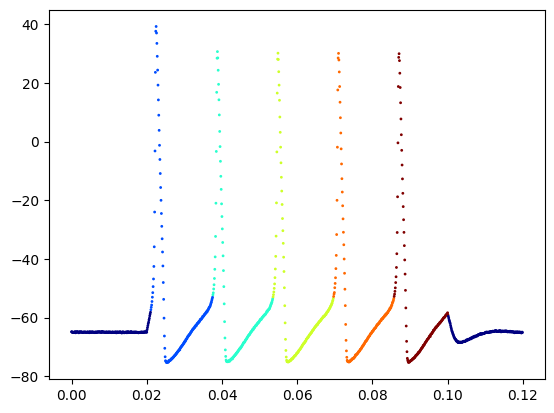

In [5]:
spike_ids = np.asarray(ev.spikes)
n_spikes = int(spike_ids.max())
cmap = plt.get_cmap("jet", n_spikes + 2)  # +2 to include -1 and all spike ids

colors = cmap((spike_ids + 1) / (n_spikes + 1))  # shift so -1 -> 0
plt.scatter(np.asarray(t), np.asarray(v), color=colors, s=1)

In [ ]:
# todo: in detect events make t0 and t1 arrays
# todo allow to deal with time-series that have different lengths, by padding

In [ ]:
from allen_ephys.ephys_extractor import EphysSweepSetFeatureExtractor, EphysSweepFeatureExtractor, EphysCellFeatureExtractor

# TODO: get rid of match_data utilities, slim down conftest as well if possible. 
# todo this you can label the data with has_spikes, is_hyperpol, then for integrity testing replace specimen_case.representative_sweep(sweep_kind) with data["v"][stim_names == "short" & has_spikes == True][0] or similar.

# TODO: define "fast" flag that checks only one specimen and slow which checks all 5 specimens for all parity testing both for allen_ephys as well as for the re-implementation in jax.
specimen_id = "cell_469801138"
data = np.load(f"tests/data/{specimen_id}_data.npz", allow_pickle=True)
metadata = json.loads(Path(f"tests/data/{specimen_id}_meta.json").read_text(encoding="utf-8"))
# TODO: reformat load_testdata and just store / use the nwb as is. since allen loads it anyway instead of saving the data in a custom format. If needed add PyNWB as dev dependency. To work with it, we can add helpers / convencience functions to a tests/utils/nwb_utils.py 
# TODO: add test for cell_extractor_for_nwb against imported features.

# test sweep features against data
start = data["stimulus_start_times"]
end = start + data["stimulus_durations"]
id_set = data["sweep_ids"]
stim_names = data["stimulus_names"]

t_set_long = data["t"][stim_names == "Long Square"].tolist()
v_set_long = data["v"][stim_names == "Long Square"].tolist()
i_set_long = data["i"][stim_names == "Long Square"].tolist()
id_set_long = id_set[stim_names == "Long Square"]

t_set_short = data["t"][stim_names == "Short Square"].tolist()
v_set_short = data["v"][stim_names == "Short Square"].tolist()
i_set_short = data["i"][stim_names == "Short Square"].tolist()
id_set_short = id_set[stim_names == "Short Square"]

t_set_ramp = data["t"][stim_names == "Ramp"].tolist()
v_set_ramp = data["v"][stim_names == "Ramp"].tolist()
i_set_ramp = data["i"][stim_names == "Ramp"].tolist()
id_set_ramp = id_set[stim_names == "Ramp"]

# test single sweep feature extractors against data
single_sweep_ext = EphysSweepFeatureExtractor(t_set_long[0], v_set_long[0], i_set_long[0], start=start[0], end=end[0], id=id_set_long[0])
# TODO: assert against data

# test sweep set feature extractors against data
long_ext = EphysSweepSetFeatureExtractor(t_set_long, v_set_long, i_set_long, start=start, end=end, id_set=id_set_long)
short_ext = EphysSweepSetFeatureExtractor(t_set_short, v_set_short, i_set_short, start=start, end=end, id_set=id_set_short)
ramp_ext = EphysSweepSetFeatureExtractor(t_set_ramp, v_set_ramp, i_set_ramp, start=start, end=end, id_set=id_set_ramp)

sweep_fts_data = metadata["selected_sweeps"]

long_ext.process_spikes()
sweep_fts_long = {sweep.id: sweep._sweep_features() for sweep in id_set_long.sweeps}
sweep_fts_short = {sweep.id: sweep._sweep_features() for sweep in id_set_short.sweeps}
sweep_fts_ramp = {sweep.id: sweep._sweep_features() for sweep in id_set_ramp.sweeps}

# TODO: assert dicts matching, print which keys are not matching if assertion fails "(true vs. pred) | key1:": (true, pred), "key2": (true, pred), etc.
for id in id_set_long:
    assert sweep_fts_long[id] == sweep_fts_data[id]
for id in id_set_short:
    assert sweep_fts_short[id] == sweep_fts_data[id]
for id in id_set_ramp:
    assert sweep_fts_ramp[id] == sweep_fts_data[id]

# test cell features against data
cell = EphysCellFeatureExtractor(ramp_ext, short_ext, long_ext)
cell.process_cell_features()

# TODO: assert cell features against data